In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import h2o
from h2o.automl import H2OAutoML

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "music"

# 세미콜론 구분 + 소수점 쉼표
na = ["#VALUE!", "#value", "#N/A", "NA", ""]
df = pd.read_csv(DATA / "subject-info.csv", sep=";", decimal=",", na_values=na)
print("shape:", df.shape)   # (992, 103)


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shape: (992, 103)


In [2]:
exit_col, cod_col = "Exit of the study", "Cause of death"
fu = [c for c in df.columns if c.startswith("Follow-up")][0]

# 추적 소실(1), 심장이식(2) 제외. 라벨 = 추적 기간 중 SCD(코드 3)
base = df.loc[~df[exit_col].isin([1, 2])].copy()
base["label_scd"] = (base[cod_col] == 3).astype(int)

# 나이 ">89" 1명 제외 후 숫자로 변환
base = base.loc[base["Age"].astype(str).str.strip() != ">89"].copy()
base["Age"] = pd.to_numeric(base["Age"])
print("환자:", len(base), "| SCD:", base["label_scd"].sum())   # 960 / 94


환자: 960 | SCD: 94


In [3]:
def col_letter(i):
    s, i = "", i + 1
    while i:
        i, r = divmod(i - 1, 26)
        s = chr(65 + r) + s
    return s
letters = {c: col_letter(i) for i, c in enumerate(df.columns)}   # Average RR 중복 구분용

def make_xy(base):
    base = base.copy()

    # 999 -> NaN (PR, SVPB). 측정 불가 표시(주로 심방세동)
    for c in ["PR interval (ms)", "Number of supraventricular premature beats in 24h"]:
        base[c] = pd.to_numeric(base[c], errors="coerce").replace(999, np.nan)

    # ID, 결과 정보(누수), 시각 문자열, Longest RR, VPC/h(24h 개수와 중복) 제외
    drop_cols = ["Patient ID", exit_col, cod_col, fu, "days_4years", "Holter onset (hh:mm:ss)"]
    drop_cols += [c for c in base.columns if "Longest RR" in c]
    drop_cols += [c for c in base.columns if "ventricular premature contractions per hour" in c.lower()]

    y = base["label_scd"].copy()
    X = base.drop(columns=drop_cols + ["label_scd"])

    # Average RR 중복: BO=고해상도 ECG, BV=Holter (열 위치 기반 추정)
    rr_map = {c: f"Average RR (ms) [{'ECG' if letters[c] == 'BO' else 'Holter'}]"
              for c in X.columns if re.sub(r"\s+", " ", c).strip() == "Average RR (ms)"}
    X = X.rename(columns=rr_map)
    X.columns = [re.sub(r"\s+", " ", c).strip() for c in X.columns]
    assert X.columns.is_unique, X.columns[X.columns.duplicated()].tolist()

    def find(key):
        hits = [c for c in X.columns if key.lower() in c.lower()]
        assert len(hits) == 1, (key, hits)
        return hits[0]

    # 순서 없는 범주형 코드 -> 문자열
    # PSVT의 9 = 만성 AF로 해당 없음(코드표 정의). 결측이 아니라 하나의 범주(c9)로 둔다
    cat_keys = ["etiology", "implantable", "revascularization", "mitral flow",
                "intraventricular conduction", "ecg rhythm", "holter rhythm",
                "paroxysmal supraventricular"]
    cat_cols = [find(k) for k in cat_keys]
    for c in cat_cols:
        s = pd.to_numeric(X[c], errors="coerce")
        X[c] = s.map(lambda v: f"c{int(v)}" if pd.notna(v) else np.nan)

    # 숫자도 범주도 아닌 컬럼이 남으면 멈춘다
    left = [c for c in X.columns if c not in cat_cols and not pd.api.types.is_numeric_dtype(X[c])]
    assert not left, left
    return X, y, cat_cols


In [4]:
X_chk, y_chk, cats_chk = make_xy(base)
print("X:", X_chk.shape, "| 범주형 수:", len(cats_chk))
print(X_chk[[c for c in cats_chk if "Paroxysmal" in c][0]].value_counts(dropna=False))


X: (960, 95) | 범주형 수: 8
Paroxysmal supraventricular tachyarrhythmia
c0     444
c9     256
c1     191
NaN     64
c2       4
c3       1
Name: count, dtype: int64


In [5]:
h2o.connect(ip="127.0.0.1", port=54321)

def run_automl(X, y, cat_cols, tag):
    data = X.copy()
    data.columns = [str(c) for c in data.columns]
    cat_cols = [str(c) for c in cat_cols]
    data["label_scd"] = y.values

    hf = h2o.H2OFrame(data, column_types={c: "enum" for c in cat_cols})
    hf["label_scd"] = hf["label_scd"].asfactor()
    split = hf["label_scd"].stratified_split(test_frac=0.2, seed=42)
    train, test = hf[split == "train"], hf[split == "test"]
    predictors = [c for c in hf.columns if c != "label_scd"]

    aml = H2OAutoML(max_models=20, max_runtime_secs=900, nfolds=5, sort_metric="AUCPR",
                    include_algos=["GBM", "DRF", "XGBoost"], seed=42)
    aml.train(x=predictors, y="label_scd", training_frame=train)
    leader = aml.leader
    perf = leader.model_performance(test)
    print(f"[{tag}] n={len(X)} | SCD={int(y.sum())} | 모델: {leader.model_id}")
    print(f"[{tag}] test AUC {perf.auc():.3f} | AUCPR {perf.aucpr():.3f} | 무작위 기준 {y.mean():.3f}")

    # SHAP (단위: log-odds)
    contrib = leader.predict_contributions(test, output_format="compact").as_data_frame()
    contrib = contrib.drop(columns=["BiasTerm"])
    feat = test[predictors].as_data_frame()
    assert set(contrib.columns) == set(feat.columns), set(contrib.columns) ^ set(feat.columns)
    contrib = contrib[feat.columns]

    feat_num = feat.copy()
    for c in cat_cols:
        feat_num[c] = feat_num[c].astype("category").cat.codes.replace(-1, np.nan)
    feat_num = feat_num.apply(pd.to_numeric, errors="coerce")

    shap.summary_plot(contrib.values, feat_num, max_display=20, show=False)
    plt.title(f"SHAP - {tag}"); plt.tight_layout(); plt.show()

    imp = contrib.abs().mean().sort_values(ascending=False)
    return {"aml": aml, "leader": leader, "perf": perf, "imp": imp, "test": test}



Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,46 secs
H2O_cluster_timezone:,Asia/Seoul
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,2 months and 8 days
H2O_cluster_name:,poc_local
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.977 Gb
H2O_cluster_total_cores:,20
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


A: (960, 95)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
[A] n=960 | SCD=94 | 모델: XGBoost_1_AutoML_1_20261019_224642
[A] test AUC 0.649 | AUCPR 0.130 | 무작위 기준 0.098
contributions progress: |████████████████████████████████████████████████████████| (done) 100%


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


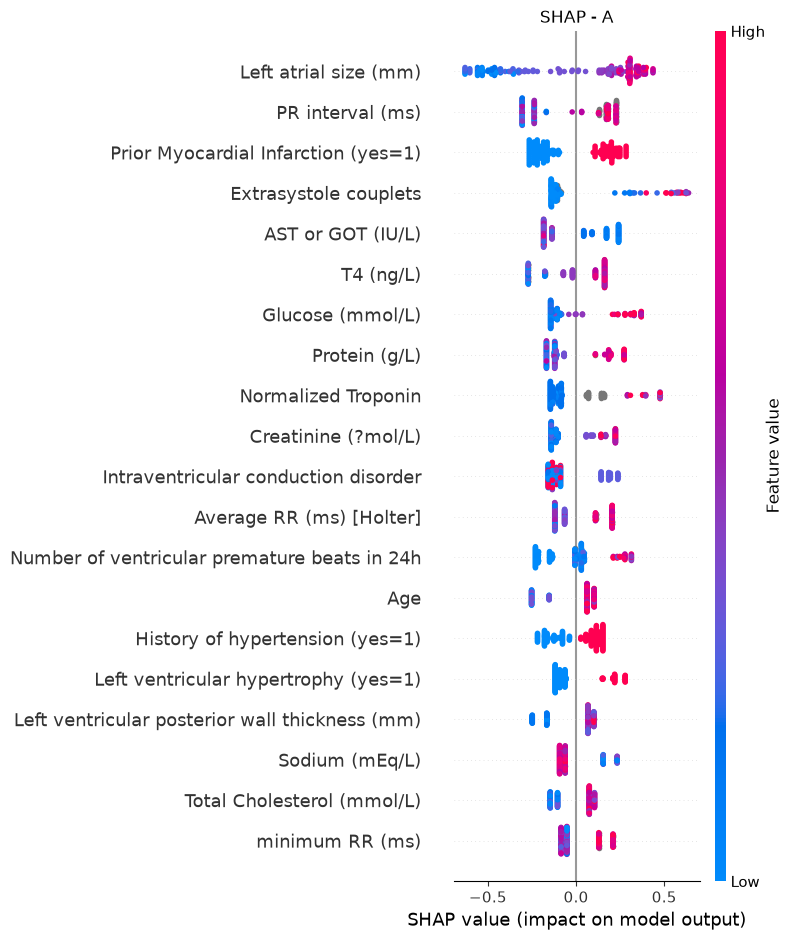

model_id
XGBoost    9
GBM        9
XRT        1
DRF        1
Name: count, dtype: int64


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


In [6]:
XA, yA, cat_cols = make_xy(base)
print("A:", XA.shape)   # (960, 95)
resA = run_automl(XA, yA, cat_cols, "A")

# 20개 모델이 어떤 알고리즘으로 만들어졌는지
lbA = resA["aml"].leaderboard.as_data_frame()
print(lbA["model_id"].str.split("_").str[0].value_counts())


In [7]:
lb = resA["aml"].leaderboard.as_data_frame()
rows = []
for mid in lb["model_id"]:
    m = h2o.get_model(mid)
    p = m.actual_params
    s = m._model_json["output"]["model_summary"].as_data_frame()   # 실제로 만들어진 트리 정보
    rows.append({
        "model": mid.split("_AutoML")[0],
        "트리수(실제)": s["number_of_trees"].iloc[0] if "number_of_trees" in s else None,
        "max_depth": p.get("max_depth"),
        "learn_rate": p.get("learn_rate"),
        "min_rows": p.get("min_rows"),
        "sample_rate": p.get("sample_rate"),
        "col_sample_rate": p.get("col_sample_rate"),
    })
info = pd.DataFrame(rows)
info["cv_aucpr"] = lb["aucpr"].round(3).values
info["cv_auc"] = lb["auc"].round(3).values
print(info.to_string())


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


             model  트리수(실제)  max_depth  learn_rate  min_rows  sample_rate  col_sample_rate  cv_aucpr  cv_auc
0        XGBoost_1     33.0         15         0.3      10.0        0.600              0.8     0.185   0.636
1       GBM_grid_1     22.0         11         0.1      10.0        0.600              1.0     0.179   0.664
2   XGBoost_grid_1     42.0          3         0.3       3.0        0.800              0.6     0.174   0.673
3       GBM_grid_1     22.0          6         0.1       1.0        0.500              0.7     0.171   0.660
4            XRT_1     43.0         20         NaN       1.0        0.632              NaN     0.169   0.647
5        XGBoost_3     32.0          5         0.3       3.0        0.800              0.8     0.169   0.635
6            GBM_2     21.0          7         0.1      10.0        0.800              0.8     0.164   0.642
7   XGBoost_grid_1     42.0         12         0.3      20.0        0.800              0.6     0.159   0.642
8   XGBoost_grid_1 

B: (788, 95)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
[B] n=788 | SCD=94 | 모델: XGBoost_grid_1_AutoML_2_20261019_224709_model_3
[B] test AUC 0.638 | AUCPR 0.158 | 무작위 기준 0.119
contributions progress: |████████████████████████████████████████████████████████| (done) 100%


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


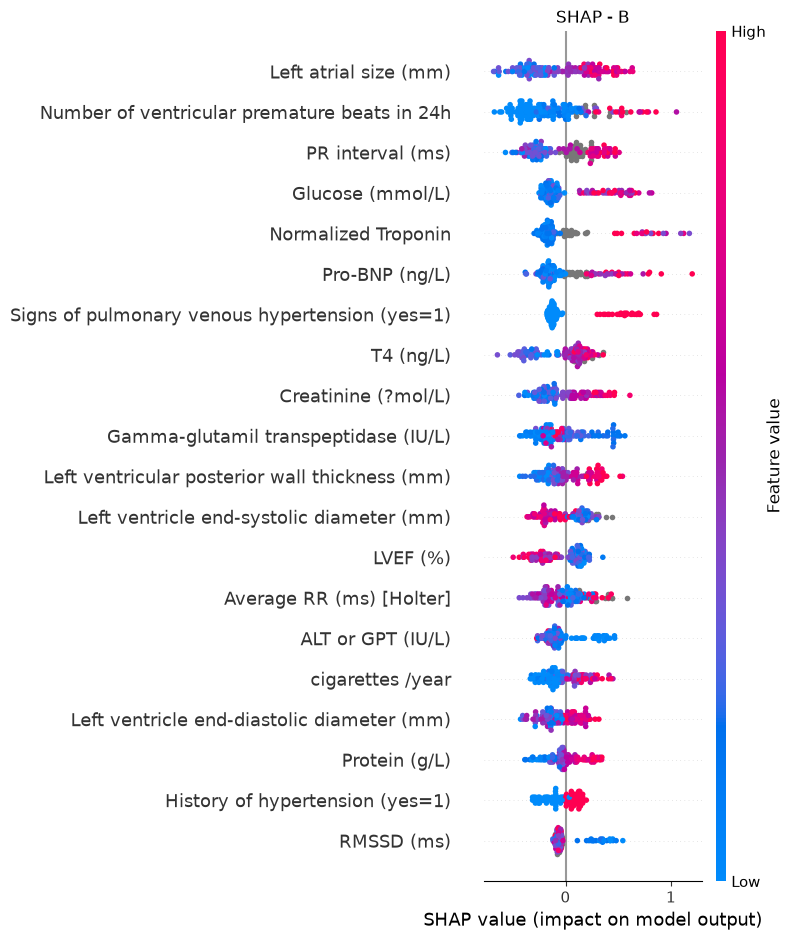

model_id
XGBoost    9
GBM        9
DRF        1
XRT        1
Name: count, dtype: int64


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


In [8]:
# B안: 다른 원인(비심장성 1, 펌프 실패 6/7)으로 사망한 환자 제외
base_B = base.loc[~base[cod_col].isin([1, 6, 7])]
XB, yB, _ = make_xy(base_B)
print("B:", XB.shape)   # (788, 95)
resB = run_automl(XB, yB, cat_cols, "B")

# 20개 모델이 어떤 알고리즘으로 만들어졌는지
lbB = resB["aml"].leaderboard.as_data_frame()
print(lbB["model_id"].str.split("_").str[0].value_counts())


In [9]:
imp_A, imp_B = resA["imp"], resB["imp"]
rank = pd.DataFrame({
    "A_순위": imp_A.rank(ascending=False).astype(int),
    "B_순위": imp_B.rank(ascending=False).astype(int),
    "A_값": imp_A.round(4),
    "B_값": imp_B.round(4),
})
top = rank[(rank["A_순위"] <= 15) | (rank["B_순위"] <= 15)].sort_values("B_순위")
print(top.to_string())

print("\n상위 15개 겹침:", len(set(imp_A.head(15).index) & set(imp_B.head(15).index)), "/ 15")
print("전체 순위 상관(Spearman):", round(rank["A_순위"].corr(rank["B_순위"], method="spearman"), 3))


                                                A_순위  B_순위     A_값     B_값
Left atrial size (mm)                              1     1  0.3345  0.2955
Number of ventricular premature beats in 24h      13     2  0.1264  0.2932
PR interval (ms)                                   2     3  0.2236  0.2441
Glucose (mmol/L)                                   7     4  0.1604  0.2326
Normalized Troponin                                9     5  0.1492  0.2324
Pro-BNP (ng/L)                                    23     6  0.0886  0.2128
Signs of pulmonary venous hypertension (yes=1)    32     7  0.0719  0.2082
T4 (ng/L)                                          6     8  0.1678  0.1949
Creatinine (?mol/L)                               10     9  0.1444  0.1924
Gamma-glutamil transpeptidase (IU/L)              36    10  0.0678  0.1886
Left ventricular posterior wall thickness (mm)    17    11  0.1178  0.1731
Left ventricle end-systolic diameter (mm)         25    12  0.0866  0.1724
LVEF (%)                 

In [10]:
# A의 상위 모델 5개(XGBoost/GBM만)로 SHAP 중요도를 구하고 평균 낸다
# DRF/XRT 제외 이유: XRT는 SHAP 덧셈 검증 실패(계산 오류), DRF는 단위가 확률이라 log-odds와 섞을 수 없음
lb = resA["aml"].leaderboard.as_data_frame()
test_A = resA["test"]
ids = [m for m in lb["model_id"] if m.startswith(("XGBoost", "GBM"))][:5]

imps = {}
for i, mid in enumerate(ids):
    m = h2o.get_model(mid)
    c = m.predict_contributions(test_A, output_format="compact").as_data_frame()

    # 덧셈 검증: SHAP 합 + BiasTerm = logit(예측 확률)
    p1 = m.predict(test_A).as_data_frame()["p1"].clip(1e-9, 1 - 1e-9).values
    err = np.abs(c.sum(axis=1).values - np.log(p1 / (1 - p1))).max()
    assert err < 1e-3, (mid, err)

    imp = c.drop(columns=["BiasTerm"]).abs().mean()
    imps[f"{i+1}_{mid.split('_AutoML')[0]}"] = imp / imp.sum()   # 모델마다 합이 1이 되게 맞춤

tbl = pd.DataFrame(imps)
model_cols = tbl.columns.tolist()
tbl["평균"] = tbl[model_cols].mean(axis=1)
tbl["상위15_횟수"] = (tbl[model_cols].rank(ascending=False) <= 15).sum(axis=1)
tbl = tbl.sort_values("평균", ascending=False)
print(tbl.head(20).round(3).to_string())


contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
contributions progress: |

...

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
                                                1_XGBoost_1  2_GBM_grid_1  3_XGBoost_grid_1  4_GBM_grid_1  5_XGBoost_3     평균  상위15_횟수
Extrasystole couplets                                 0.038         0.080             0.084         0.090        0.025  0.063        5
Left atrial size (mm)                                 0.071         0.031             0.119         0.047        0.043  0.062        5
Number of ventricular premature beats in 24h          0.027         0.015             0.087         0.034        0.042  0.041        4
PR interval (ms)                                      0.047         0.026             0.038         0.041        0.038  0.038        5
Sodium (mEq/L)                                        0.022         0.035             0.057         0.028        0.040  0.036        4
Intraventricular conducti

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


In [11]:
# B의 상위 모델 5개(XGBoost/GBM만)로 SHAP 중요도 평균 (A와 같은 방식)
lbB = resB["aml"].leaderboard.as_data_frame()
test_B = resB["test"]
idsB = [m for m in lbB["model_id"] if m.startswith(("XGBoost", "GBM"))][:5]

impsB = {}
for i, mid in enumerate(idsB):
    m = h2o.get_model(mid)
    c = m.predict_contributions(test_B, output_format="compact").as_data_frame()

    # 덧셈 검증: SHAP 합 + BiasTerm = logit(예측 확률)
    p1 = m.predict(test_B).as_data_frame()["p1"].clip(1e-9, 1 - 1e-9).values
    err = np.abs(c.sum(axis=1).values - np.log(p1 / (1 - p1))).max()
    assert err < 1e-3, (mid, err)

    imp = c.drop(columns=["BiasTerm"]).abs().mean()
    impsB[f"{i+1}_{mid.split('_AutoML')[0]}"] = imp / imp.sum()

tblB = pd.DataFrame(impsB)
colsB = tblB.columns.tolist()
tblB["평균"] = tblB[colsB].mean(axis=1)
tblB["상위15_횟수"] = (tblB[colsB].rank(ascending=False) <= 15).sum(axis=1)
tblB = tblB.sort_values("평균", ascending=False)
print(tblB.head(20).round(3).to_string())


contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
contributions progress: |

...

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
                                                1_XGBoost_grid_1  2_GBM_grid_1  3_XGBoost_grid_1  4_XGBoost_1  5_XGBoost_2     평균  상위15_횟수
Left atrial size (mm)                                      0.047         0.035             0.106        0.088        0.049  0.065        5
Pro-BNP (ng/L)                                             0.034         0.044             0.090        0.031        0.024  0.044        4
Number of ventricular premature beats in 24h               0.047         0.044             0.045        0.068        0.016  0.044        4
Extrasystole couplets                                      0.017         0.045             0.072        0.032        0.033  0.040        4
PR interval (ms)                                           0.039         0.028             0.049        0.030        0.038  0.037        4
N

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


In [12]:
# A(5개 모델 평균) vs B(5개 모델 평균) 순위 비교
tblA = tbl   # 앞 셀에서 만든 A의 결과표 (이름만 붙여 줌)

cmp = pd.DataFrame({
    "A_평균순위": tblA["평균"].rank(ascending=False).astype(int),
    "B_평균순위": tblB["평균"].rank(ascending=False).astype(int),
    "A_횟수": tblA["상위15_횟수"],
    "B_횟수": tblB["상위15_횟수"],
})
top = cmp[(cmp["A_평균순위"] <= 15) | (cmp["B_평균순위"] <= 15)].sort_values("A_평균순위")
print(top.to_string())

print("\n상위 15개 겹침:", len(set(tblA.index[:15]) & set(tblB.index[:15])), "/ 15")
print("순위 상관:", round(cmp["A_평균순위"].corr(cmp["B_평균순위"], method="spearman"), 3))


                                                A_평균순위  B_평균순위  A_횟수  B_횟수
Extrasystole couplets                                1       4     5     4
Left atrial size (mm)                                2       1     5     5
Number of ventricular premature beats in 24h         3       3     4     4
PR interval (ms)                                     4       5     5     4
Sodium (mEq/L)                                       5      10     4     3
Intraventricular conduction disorder                 6      11     4     3
Pro-BNP (ng/L)                                       7       2     3     4
Q-waves (necrosis, yes=1)                            8      17     4     2
Left ventricular posterior wall thickness (mm)       9      23     4     2
cigarettes /year                                    10       9     2     3
Average RR (ms) [Holter]                            11      21     2     2
Cardiothoracic ratio                                12      70     3     0
Protein (g/L)            

xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


[A] 임계값(교차검증으로 결정): 0.054 | 테스트 192명, SCD 19명
           값  95% CI 하한  95% CI 상한
AUROC  0.649      0.544      0.748
AUPRC  0.142      0.085      0.260
민감도    0.737      0.500      0.933
특이도    0.543      0.471      0.625
Brier  0.093      0.060      0.134
참고 - 모두에게 평균 확률만 줬을 때 Brier: 0.089

혼동행렬
         예측: 위험  예측: 안전
실제 SCD       14       5
실제 비SCD      79      94


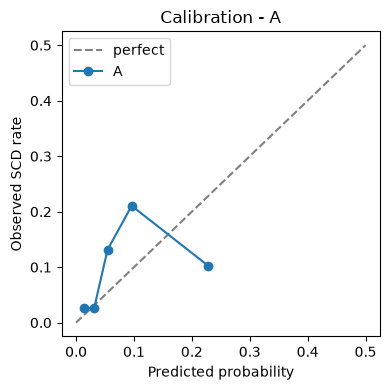

In [13]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

def evaluate(res, tag, n_boot=1000):
    leader, test = res["leader"], res["test"]

    # 1) 임계값: 테스트가 아니라 교차검증(학습 데이터) 결과로 정한다
    #    민감도 + 특이도가 가장 큰 지점 (Youden 지수)
    cv = leader.model_performance(xval=True).thresholds_and_metric_scores().as_data_frame()
    thr = float(cv.loc[(cv["tpr"] + cv["tnr"]).idxmax(), "threshold"])

    # 2) 테스트 환자 예측
    p = leader.predict(test).as_data_frame()["p1"].values
    yt = test["label_scd"].as_data_frame()["label_scd"].astype(int).values

    def metrics(yy, pp):
        pred = (pp >= thr).astype(int)
        tp = ((pred == 1) & (yy == 1)).sum(); fn = ((pred == 0) & (yy == 1)).sum()
        tn = ((pred == 0) & (yy == 0)).sum(); fp = ((pred == 1) & (yy == 0)).sum()
        return {"AUROC": roc_auc_score(yy, pp), "AUPRC": average_precision_score(yy, pp),
                "민감도": tp / (tp + fn), "특이도": tn / (tn + fp),
                "Brier": brier_score_loss(yy, pp)}

    # 3) 부트스트랩 95% CI: 테스트 환자를 복원추출로 1000번 다시 뽑아 지표가 얼마나 흔들리는지 본다
    rng = np.random.default_rng(42)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(yt), len(yt))
        if 0 < yt[i].sum() < len(i):
            boots.append(metrics(yt[i], p[i]))
    boots = pd.DataFrame(boots)

    summary = pd.DataFrame({"값": pd.Series(metrics(yt, p)),
                            "95% CI 하한": boots.quantile(0.025),
                            "95% CI 상한": boots.quantile(0.975)}).round(3)

    # 4) 혼동행렬
    pred = (p >= thr).astype(int)
    cm = pd.DataFrame([[((pred == 1) & (yt == 1)).sum(), ((pred == 0) & (yt == 1)).sum()],
                       [((pred == 1) & (yt == 0)).sum(), ((pred == 0) & (yt == 0)).sum()]],
                      index=["실제 SCD", "실제 비SCD"], columns=["예측: 위험", "예측: 안전"])

    print(f"[{tag}] 임계값(교차검증으로 결정): {thr:.3f} | 테스트 {len(yt)}명, SCD {yt.sum()}명")
    print(summary.to_string())
    print(f"참고 - 모두에게 평균 확률만 줬을 때 Brier: {brier_score_loss(yt, np.full(len(yt), yt.mean())):.3f}")
    print("\n혼동행렬")
    print(cm.to_string())

    # 5) Calibration plot: 모델이 말한 확률 vs 실제 SCD 비율
    frac, mean_p = calibration_curve(yt, p, n_bins=5, strategy="quantile")
    plt.figure(figsize=(4, 4))
    plt.plot([0, 0.5], [0, 0.5], "--", color="gray", label="perfect")
    plt.plot(mean_p, frac, "o-", label=tag)
    plt.xlabel("Predicted probability"); plt.ylabel("Observed SCD rate")
    plt.title(f"Calibration - {tag}"); plt.legend(); plt.tight_layout(); plt.show()
    return {"thr": thr, "summary": summary, "cm": cm}

evalA = evaluate(resA, "A")


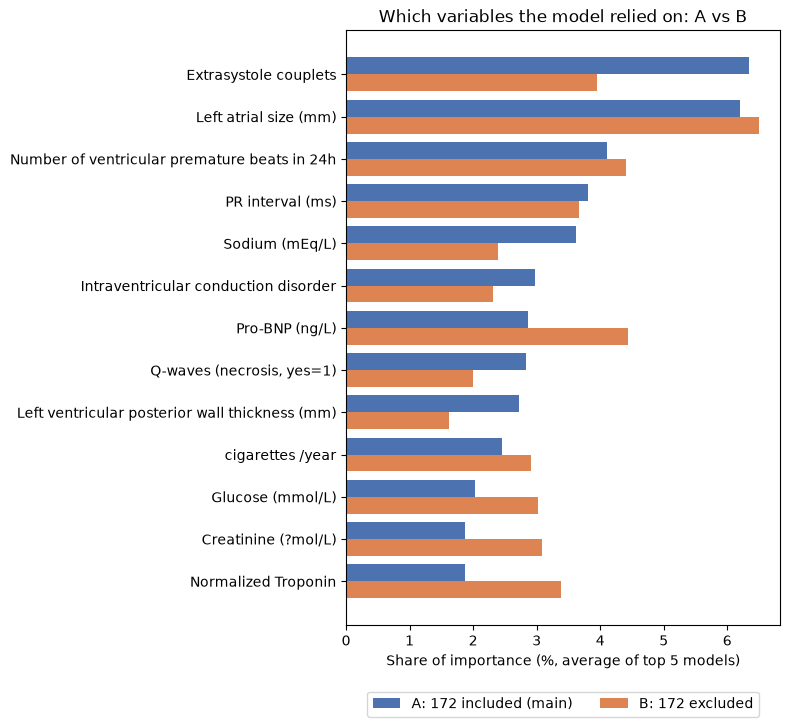

In [16]:
# A vs B: 상위 5개 모델 평균 중요도(비중) 비교 막대 그래프
top_vars = list(dict.fromkeys(list(tblA.index[:10]) + list(tblB.index[:10])))   # A나 B의 상위 10개 합집합
d = pd.DataFrame({"A": tblA.loc[top_vars, "평균"], "B": tblB.loc[top_vars, "평균"]}) * 100
d = d.sort_values("A")   # 가로 막대는 아래부터 그려서, A에서 중요한 변수가 위로 오게 정렬

y = np.arange(len(d)); h = 0.4
fig, ax = plt.subplots(figsize=(8, 0.45 * len(d) + 1.5))
ax.barh(y + h / 2, d["A"], h, label="A: 172 included (main)", color="#4C72B0")
ax.barh(y - h / 2, d["B"], h, label="B: 172 excluded", color="#DD8452")
ax.set_yticks(y); ax.set_yticklabels(d.index)
ax.set_xlabel("Share of importance (%, average of top 5 models)")
ax.set_title("Which variables the model relied on: A vs B")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.savefig(ROOT / "shap_A_vs_B_bar.png", dpi=150, bbox_inches="tight")
plt.show()


contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
contributions progress: |

...

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%
contributions progress: |

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


████████████████████████████████████████████████████████| (done) 100%


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


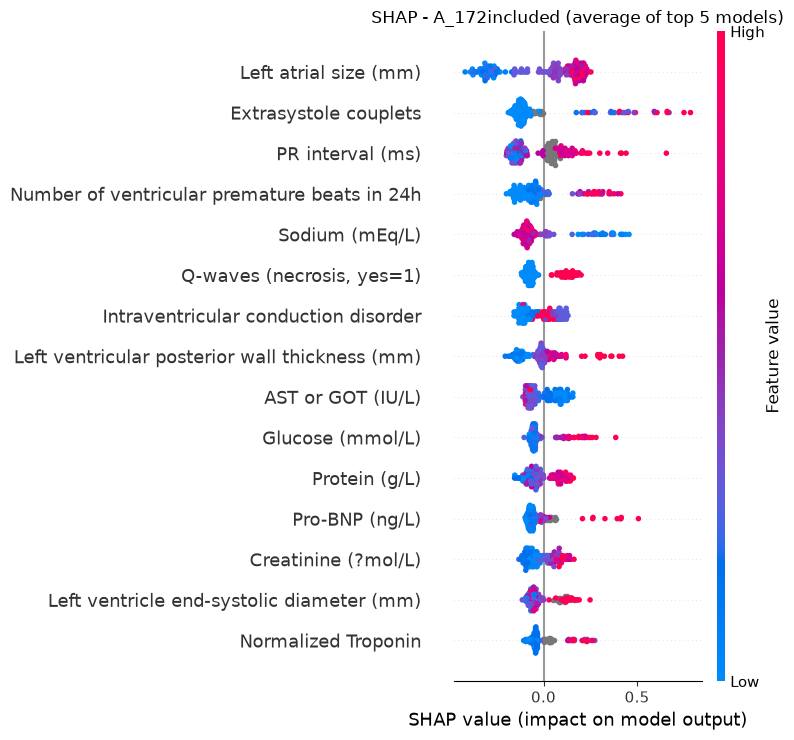

In [15]:
# 상위 5개 모델(XGBoost/GBM)의 환자별 SHAP을 평균 내서 그래프 그리기
def avg_shap_plot(res, tag, n=5):
    lb = res["aml"].leaderboard.as_data_frame()
    test = res["test"]
    ids = [m for m in lb["model_id"] if m.startswith(("XGBoost", "GBM"))][:n]
    predictors = [c for c in test.columns if c != "label_scd"]
    feat = test[predictors].as_data_frame()

    contribs = []
    for mid in ids:
        c = h2o.get_model(mid).predict_contributions(test, output_format="compact").as_data_frame()
        contribs.append(c[feat.columns])        # 변수 순서 맞추기 (BiasTerm은 여기서 빠짐)
    avg = sum(contribs) / len(contribs)         # 환자별·변수별 SHAP을 5개 모델 평균

    # 점 색깔용: 범주형은 임시 숫자 코드로 (범주형 색은 의미 없음)
    feat_num = feat.copy()
    for c in feat_num.columns:
        if feat_num[c].dtype == object:
            feat_num[c] = feat_num[c].astype("category").cat.codes.replace(-1, np.nan)
    feat_num = feat_num.apply(pd.to_numeric, errors="coerce")

    shap.summary_plot(avg.values, feat_num, max_display=15, show=False)
    plt.title(f"SHAP - {tag} (average of top {len(ids)} models)")
    plt.tight_layout()
    plt.savefig(ROOT / f"shap_{tag}_avg5.png", dpi=150, bbox_inches="tight")
    plt.show()
    return avg

avgA = avg_shap_plot(resA, "A_172included")


In [17]:
# AST, Protein: 값 구간별 실제 SCD 비율 (모델 없이 원본 데이터로)
for col in ["AST or GOT (IU/L)", "Protein (g/L)"]:
    s = pd.to_numeric(XA[col], errors="coerce")
    q = pd.qcut(s, 4, labels=["1(낮음)", "2", "3", "4(높음)"])
    t = pd.DataFrame({"구간": q, "SCD": yA.values}).groupby("구간", observed=True)["SCD"]
    print(f"\n[{col}]")
    print(pd.DataFrame({"환자 수": t.size(), "SCD 수": t.sum(), "SCD 비율": t.mean().round(3),
                        "값 범위": s.groupby(q, observed=True).agg(lambda v: f"{v.min():g}~{v.max():g}")}).to_string())



[AST or GOT (IU/L)]
       환자 수  SCD 수  SCD 비율    값 범위
1(낮음)   276     28   0.101    7~16
2       237     23   0.097   17~20
3       222     18   0.081   21~25
4(높음)   225     25   0.111  26~154

[Protein (g/L)]
       환자 수  SCD 수  SCD 비율       값 범위
1(낮음)   240     21   0.088    51~68.5
2       251     22   0.088    68.6~72
3       230     22   0.096  72.1~75.9
4(높음)   238     29   0.122    76~94.8
